In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.outliers_influence import variance_inflation_factor

df = pd.read_csv("Data_project_clean.csv")

gov_cols = ["Control_of_Corruption", "Rule_of_Law", "Political_Stability",
            "Government_Effectiveness", "Regulatory_Quality", "Voice_and_Accountability"]
df["Gov_index"] = df[gov_cols].mean(axis=1)
df["GDP_growth_binary"] = (df["GDP_growth"] > 0).astype(int)

## 1. Зависимая переменная: бинарная форма

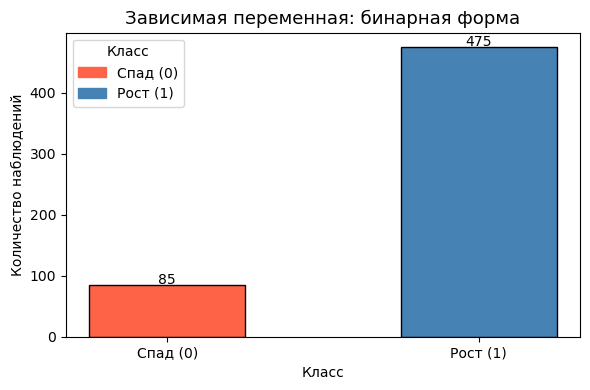

In [55]:
mean_val = df["GDP_growth"].mean()
counts = df["GDP_growth_binary"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Спад (0)", "Рост (1)"], counts.values,
        color=["tomato", "steelblue"], edgecolor="black", width=0.5)
for i, v in enumerate(counts.values):
    plt.text(i, v + 1, str(v), ha="center")
plt.title("Зависимая переменная: бинарная форма", fontsize=13)
plt.xlabel("Класс")
plt.ylabel("Количество наблюдений")
plt.legend(handles=[
    plt.Rectangle((0,0),1,1, color="tomato",    label="Спад (0)"),
    plt.Rectangle((0,0),1,1, color="steelblue", label="Рост (1)")
], title="Класс")
plt.tight_layout()
plt.show()

## Q-Q plot: нормальность распределения GDP_growth

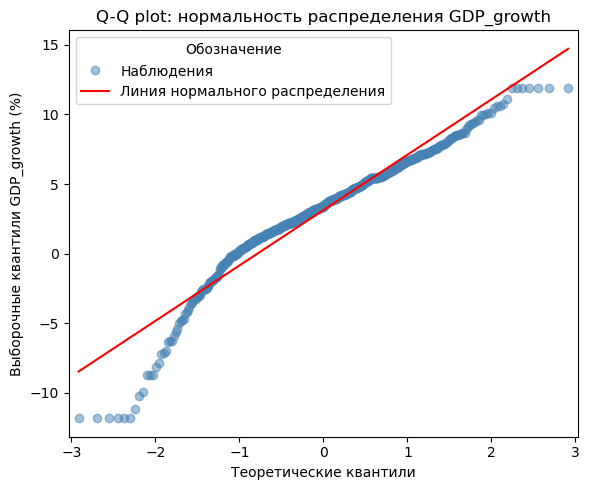

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
qqplot(df["GDP_growth"].dropna(), line="s", ax=ax, alpha=0.5,
       markerfacecolor="steelblue", markeredgecolor="steelblue")
ax.set_title("Q-Q plot: нормальность распределения GDP_growth")
ax.set_xlabel("Теоретические квантили")
ax.set_ylabel("Выборочные квантили GDP_growth (%)")
ax.legend(["Наблюдения", "Линия нормального распределения"], title="Обозначение")
plt.tight_layout()
plt.show()

## Топ-15 стран по среднему темпу роста ВВП (2010–2023)

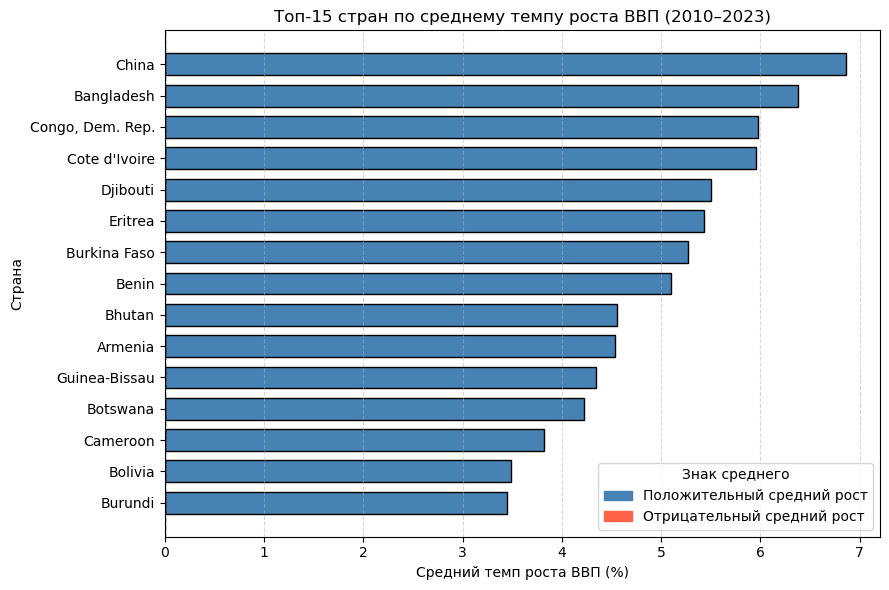

In [10]:
avg_gdp = df.groupby("Country")["GDP_growth"].mean().sort_values(ascending=True).tail(15)
colors_bar = ["steelblue" if v > 0 else "tomato" for v in avg_gdp.values]

plt.figure(figsize=(9, 6))
plt.barh(avg_gdp.index.tolist(), avg_gdp.tolist(), color=colors_bar, edgecolor="black", height=0.7)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Топ-15 стран по среднему темпу роста ВВП (2010–2023)")
plt.xlabel("Средний темп роста ВВП (%)")
plt.ylabel("Страна")
plt.legend(handles=[
    plt.Rectangle((0,0),1,1, color="steelblue", label="Положительный средний рост"),
    plt.Rectangle((0,0),1,1, color="tomato",    label="Отрицательный средний рост")
], title="Знак среднего")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Распределение темпов роста ВВП по группам дохода

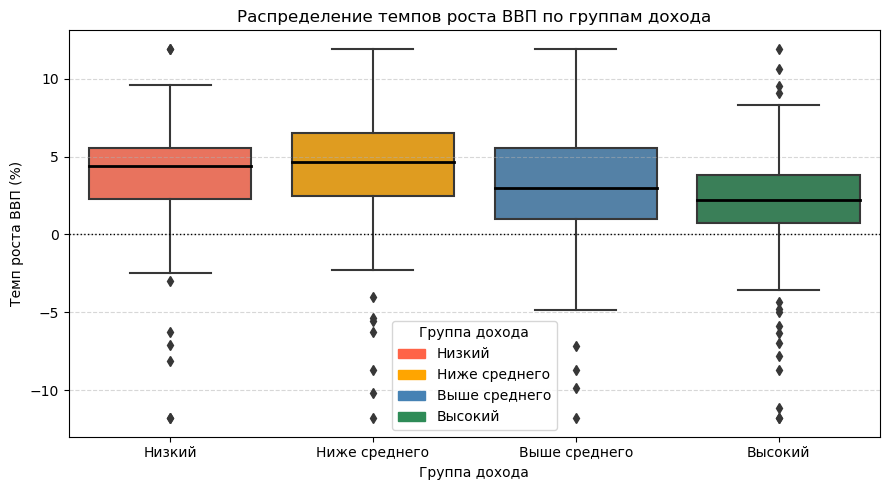

In [15]:
income_map = {"HIC": "Высокий", "UMC": "Выше среднего", "LMC": "Ниже среднего", "LIC": "Низкий"}

all_c = pd.read_csv("Data_project_clean.csv")[["Country"]].drop_duplicates()

import json, requests
resp = requests.get("https://api.worldbank.org/v2/country?format=json&per_page=1000", timeout=10)
wb = json.loads(resp.text)
income_df = pd.DataFrame([{"Country": r["name"], "Income": income_map.get(r["incomeLevel"]["id"], r["incomeLevel"]["id"])}
                           for r in wb[1] if r["incomeLevel"]["id"] in income_map])

df_inc = df.merge(income_df, on="Country", how="left")
df_inc = df_inc.dropna(subset=["Income"])

order = ["Низкий", "Ниже среднего", "Выше среднего", "Высокий"]
palette = {"Низкий": "tomato", "Ниже среднего": "orange",
           "Выше среднего": "steelblue", "Высокий": "seagreen"}

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_inc, x="Income", y="GDP_growth", order=order,
            palette=palette, medianprops=dict(color="black", linewidth=2))
plt.axhline(0, color="black", linestyle=":", linewidth=1)
plt.title("Распределение темпов роста ВВП по группам дохода")
plt.xlabel("Группа дохода")
plt.ylabel("Темп роста ВВП (%)")
plt.legend(handles=[plt.Rectangle((0,0),1,1, color=c, label=l)
                    for l, c in palette.items()], title="Группа дохода")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Временная динамика

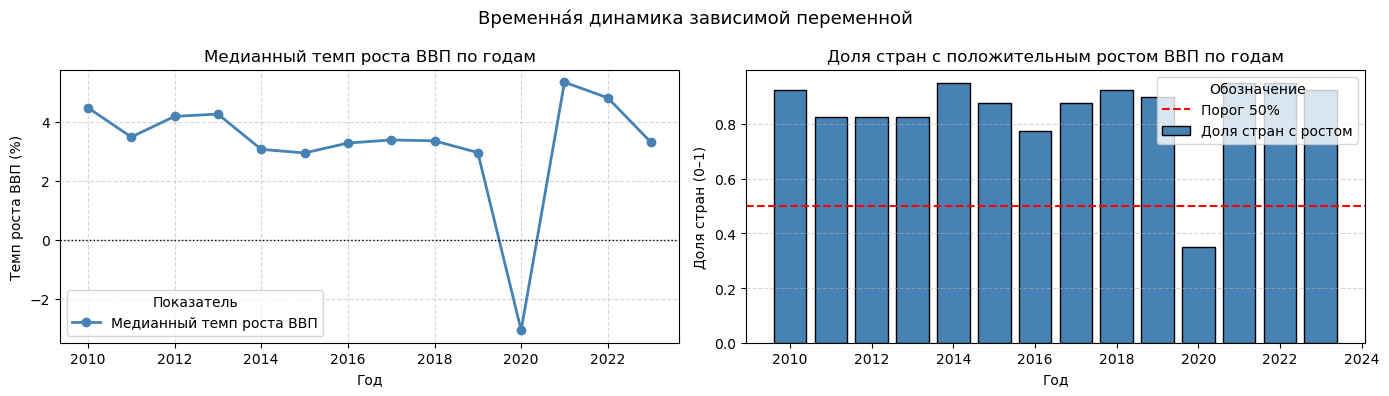

In [17]:
gdp_year = df.groupby("Year")["GDP_growth"].median().reset_index()
share_pos = df.groupby("Year")["GDP_growth_binary"].mean().reset_index()
share_pos.columns = ["Year", "Share_positive"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(gdp_year["Year"], gdp_year["GDP_growth"],
             marker="o", color="steelblue", linewidth=2, label="Медианный темп роста ВВП")
axes[0].axhline(0, color="black", linestyle=":", linewidth=1)
axes[0].set_title("Медианный темп роста ВВП по годам")
axes[0].set_xlabel("Год")
axes[0].set_ylabel("Темп роста ВВП (%)")
axes[0].legend(title="Показатель")
axes[0].grid(linestyle="--", alpha=0.5)

axes[1].bar(share_pos["Year"], share_pos["Share_positive"],
            color="steelblue", edgecolor="black", label="Доля стран с ростом")
axes[1].axhline(0.5, color="red", linestyle="--", linewidth=1.5, label="Порог 50%")
axes[1].set_title("Доля стран с положительным ростом ВВП по годам")
axes[1].set_xlabel("Год")
axes[1].set_ylabel("Доля стран (0–1)")
axes[1].legend(title="Обозначение")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Временная динамика зависимой переменной", fontsize=13)
plt.tight_layout()
plt.show()

## Тепловая карта корреляций

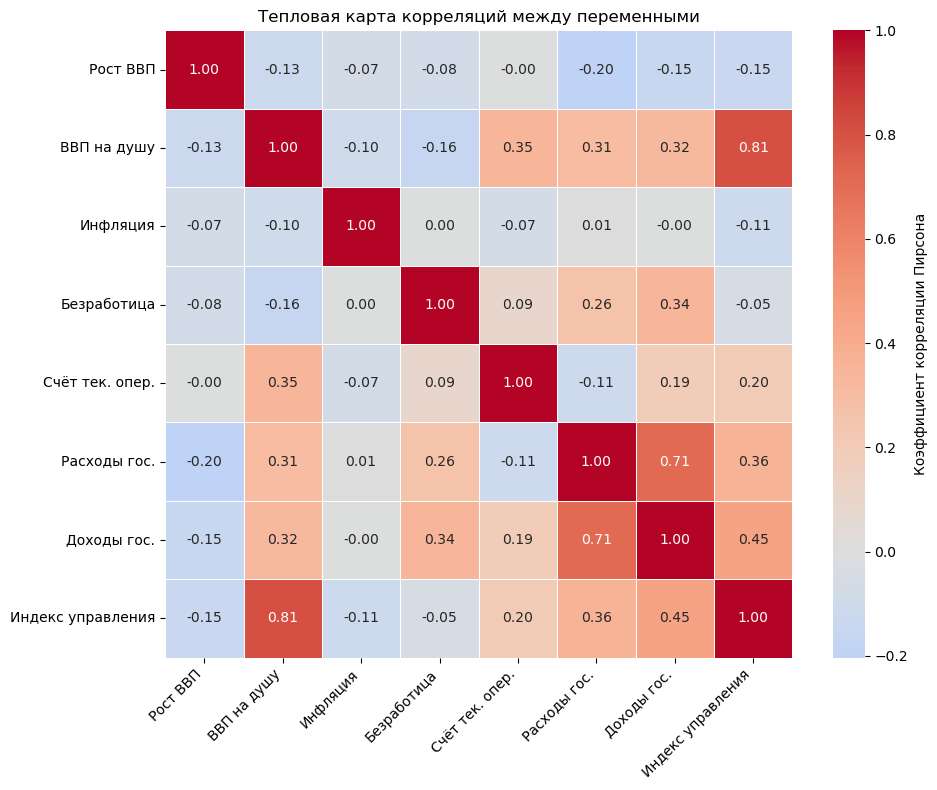

In [20]:
corr_vars = ["GDP_growth", "GDP_per_capita", "Inflation", "Unemployment",
             "Current_account", "Gov_expenditure", "Gov_revenue", "Gov_index"]
corr_labels = ["Рост ВВП", "ВВП на душу", "Инфляция", "Безработица",
               "Счёт тек. опер.", "Расходы гос.", "Доходы гос.", "Индекс управления"]

corr_m = df[corr_vars].corr()
corr_m.index = corr_labels
corr_m.columns = corr_labels

plt.figure(figsize=(10, 8))
sns.heatmap(corr_m, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, square=True, cbar_kws={"label": "Коэффициент корреляции Пирсона"})
plt.title("Тепловая карта корреляций между переменными")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## VIF: диагностика мультиколлинеарности предикторов

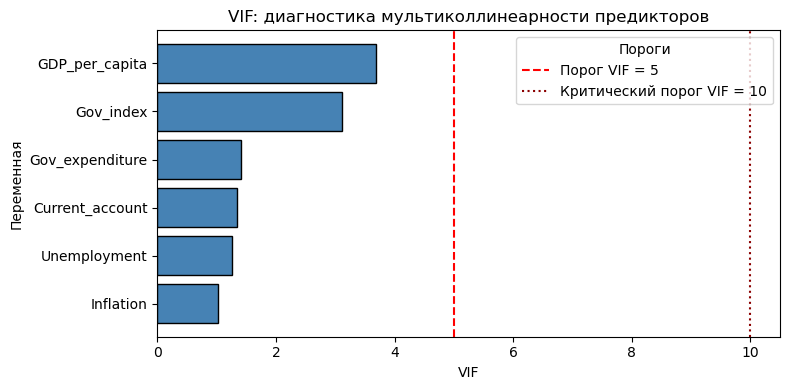

In [23]:
vif_vars = ["GDP_per_capita", "Inflation", "Unemployment",
            "Current_account", "Gov_expenditure", "Gov_index"]
X_vif = sm.add_constant(df[vif_vars].dropna())

vif_df = pd.DataFrame({
    "Переменная": vif_vars,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(vif_vars))]
}).sort_values("VIF", ascending=True)

colors = ["tomato" if v > 5 else "steelblue" for v in vif_df["VIF"]]

plt.figure(figsize=(8, 4))
plt.barh(vif_df["Переменная"], vif_df["VIF"], color=colors, edgecolor="black")
plt.axvline(5,  color="red",     linestyle="--", linewidth=1.5, label="Порог VIF = 5")
plt.axvline(10, color="darkred", linestyle=":",  linewidth=1.5, label="Критический порог VIF = 10")
plt.title("VIF: диагностика мультиколлинеарности предикторов")
plt.xlabel("VIF")
plt.ylabel("Переменная")
plt.legend(title="Пороги")
plt.tight_layout()
plt.show()

## Распределения предикторов после очистки данных

C:\Users\Public\Downloads\Pyton\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Public\Downloads\Pyton\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Public\Downloads\Pyton\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Public\Downloads\Pyton\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf va

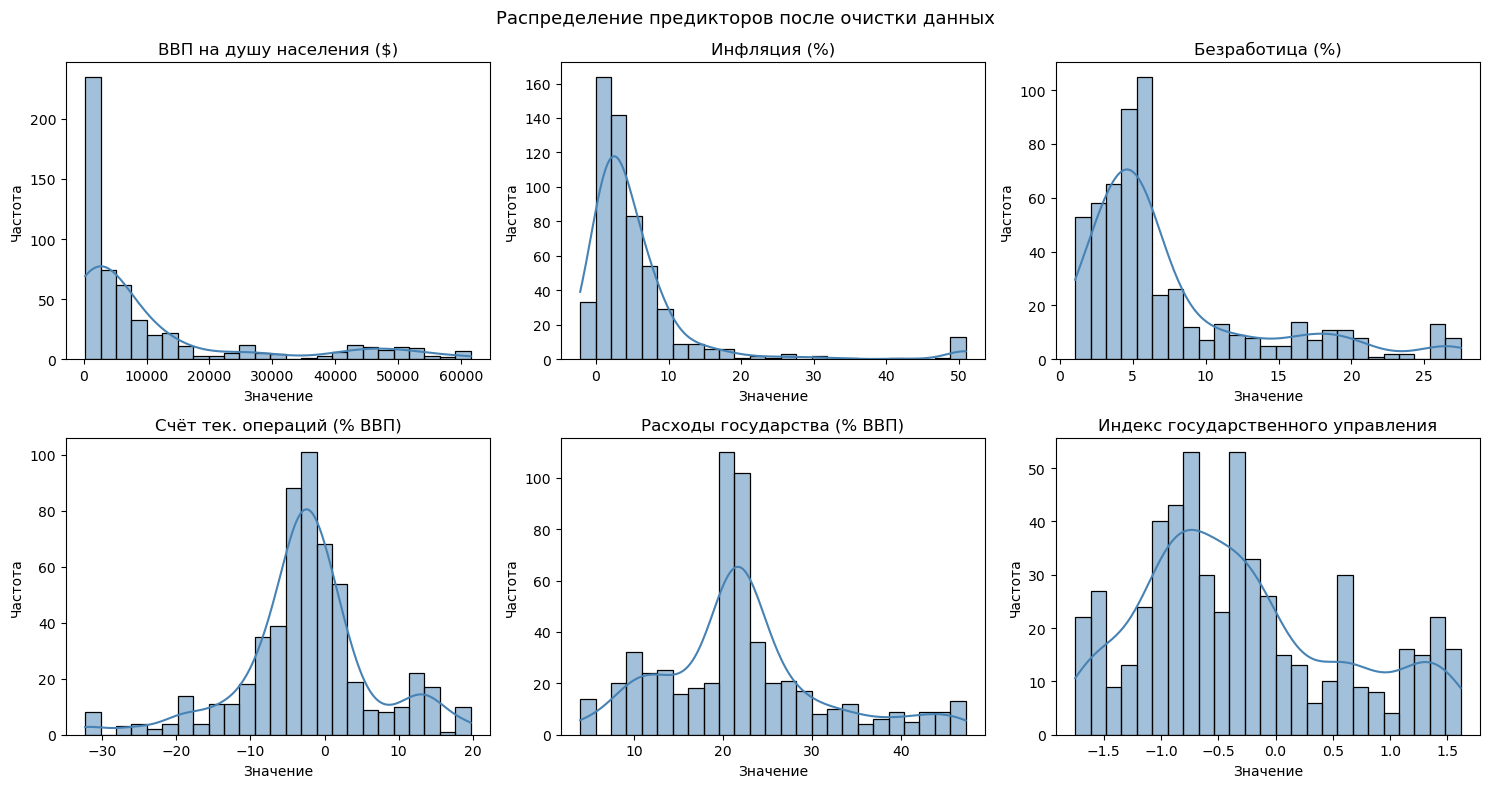

In [26]:
plot_vars = [
    ("GDP_per_capita",  "ВВП на душу населения ($)"),
    ("Inflation",       "Инфляция (%)"),
    ("Unemployment",    "Безработица (%)"),
    ("Current_account", "Счёт тек. операций (% ВВП)"),
    ("Gov_expenditure", "Расходы государства (% ВВП)"),
    ("Gov_index",       "Индекс государственного управления")
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (var, label) in zip(axes.flatten(), plot_vars):
    sns.histplot(df[var], bins=25, kde=True, ax=ax, color="steelblue")
    ax.set_title(label)
    ax.set_xlabel("Значение")
    ax.set_ylabel("Частота")

plt.suptitle("Распределение предикторов после очистки данных", fontsize=13)
plt.tight_layout()
plt.show()